# Методы моделирования профилей медиапотребления

## Подключение библиотек

In [61]:
import pandas as pd
import csv
import os
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


Так как данные представляют собой логи, разделим их на несколько таблиц.

In [2]:
os.makedirs("processed", exist_ok=True)

sessions_file = open("processed/sessions.csv", "w", newline="", encoding="utf-8")
queries_file = open("processed/queries.csv", "w", newline="", encoding="utf-8")
clicks_file = open("processed/clicks.csv", "w", newline="", encoding="utf-8")
results_file = open("processed/results.csv", "w", newline="", encoding="utf-8")

sessions_writer = csv.writer(sessions_file)
queries_writer = csv.writer(queries_file)
clicks_writer = csv.writer(clicks_file)
results_writer = csv.writer(results_file)

In [3]:
sessions = []
queries = []
clicks = []
results = []

with open("train", "r", encoding="utf-8") as f:

    for i, line in enumerate(f):

        fields = line.rstrip("\r\n").split("\t")

        if len(fields) > 1 and fields[1] == "M":
            sessions.append(fields[:1] + fields[2:])

        elif len(fields) > 2 and fields[2] == "Q":
            queries.append(fields[:2] + fields[3:])

        elif len(fields) > 2 and fields[2] == "C":
            clicks.append(fields[:2] + fields[3:])

        elif len(fields) > 2 and fields[2] == "T":
            results.append(fields[:2] + fields[3:])

        if len(sessions) >= 100_000:
            sessions_writer.writerows(sessions)
            sessions = []

        if len(queries) >= 100_000:
            queries_writer.writerows(queries)
            queries = []

        if len(clicks) >= 100_000:
            clicks_writer.writerows(clicks)
            clicks = []

        if len(results) >= 100_000:
            results_writer.writerows(results)
            results = []
        if i % 1_000_000 == 0:
            print(f"Обработано {i} строк")

sessions_writer.writerows(sessions)
queries_writer.writerows(queries)
clicks_writer.writerows(clicks)
results_writer.writerows(results)

sessions_file.close()
queries_file.close()
clicks_file.close()
results_file.close()


Обработано 0 строк
Обработано 1000000 строк
Обработано 2000000 строк
Обработано 3000000 строк
Обработано 4000000 строк
Обработано 5000000 строк
Обработано 6000000 строк
Обработано 7000000 строк
Обработано 8000000 строк
Обработано 9000000 строк
Обработано 10000000 строк
Обработано 11000000 строк
Обработано 12000000 строк
Обработано 13000000 строк
Обработано 14000000 строк
Обработано 15000000 строк
Обработано 16000000 строк
Обработано 17000000 строк
Обработано 18000000 строк
Обработано 19000000 строк
Обработано 20000000 строк
Обработано 21000000 строк
Обработано 22000000 строк
Обработано 23000000 строк
Обработано 24000000 строк
Обработано 25000000 строк
Обработано 26000000 строк
Обработано 27000000 строк
Обработано 28000000 строк
Обработано 29000000 строк
Обработано 30000000 строк
Обработано 31000000 строк
Обработано 32000000 строк
Обработано 33000000 строк
Обработано 34000000 строк
Обработано 35000000 строк
Обработано 36000000 строк
Обработано 37000000 строк
Обработано 38000000 строк
Об

### Таблица Sessions

Структура: <br>
session_id - id сессии<br>
day - день действия<br>
user_id - id пользователя

In [38]:
sessions_chunks = pd.read_csv(
    "processed/sessions.csv",
    header=None,
    chunksize = 100_000
)
df_sessions = next(sessions_chunks)
df_sessions = df_sessions.iloc[:, :3].copy()
df_sessions.columns = ["session_id", "day", "user_id"]
df_sessions.head()

,session_id,day,user_id
0,0,4,0
1,1,4,0
2,2,27,0
3,3,13,1
4,4,15,1


### Таблица Clicks

Структура: <br>
session_id - id сессии<br>
time_passed - время с начала сессии<br>
serp_id - id страницы поисковой выдачи<br>
url_id - id страницы, по которой кликнул пользователь

In [14]:
clicks_chunks = pd.read_csv(
    "processed/clicks.csv",
    header=None,
    chunksize = 100_000
)
df_clicks = next(clicks_chunks)
df_clicks.columns = ["session_id", "time_passed", "serp_id", "url_id"]
df_clicks.head()

,session_id,time_passed,serp_id,url_id
0,0,108,0,50628761
1,0,1080,0,50628761
2,3,162,1,35513272
3,4,27,0,31589696
4,4,86,0,6876504


### Таблица Queries

Структура: <br>
session_id - id сессии<br>
time_passed - время с начала сессии<br>
serp_id - id страницы поисковой выдачи<br>
query_id - id поискового запроса <br>
list_of_terms - список id слов запроса <br>
url_domain_pairs - список пар (UrlID, DomainID) - документы, показанные пользователю, и их домены

In [39]:
queries_chunks = pd.read_csv(
    "processed/queries.csv",
    header=None,
    chunksize=100_000
)
df_queries = next(queries_chunks)

pair_columns = df_queries.columns[5:]

df_queries["url_domain_pairs"] = df_queries[pair_columns].apply(
    lambda row: [
        tuple(map(int, str(value).split(",")))
        for value in row.dropna()
    ],
    axis=1
)

df_queries = df_queries.drop(columns=pair_columns)
df_queries.columns = ["session_id", "time_passed", "serp_id", "query_id", "list_of_terms", "url_domain_pairs"]
df_queries["list_of_terms"] = df_queries["list_of_terms"].apply(
    lambda x: [int(term) for term in x.split(",")] if pd.notna(x) else []
)
df_queries.head()

,session_id,time_passed,serp_id,query_id,list_of_terms,url_domain_pairs
0,0,0,0,10047345,"[3080290, 4098689]","[(50504886, 4217515), (9848058, 1084315), (505..."
1,1,0,0,2057953,[1093007],"[(12695453, 1284095), (20124473, 2056277), (60..."
2,2,0,0,2113437,[1148783],"[(33204613, 3248226), (2053036, 303607), (5878..."
3,3,0,0,5239394,"[2365113, 2856206, 2491775]","[(16457319, 1712204), (35513272, 3344594), (50..."
4,3,76,1,5239405,"[2365113, 2856206, 2491775, 4219157, 2383044]","[(16457319, 1712204), (35513272, 3344594), (19..."


Файл results пустой:

In [26]:
os.path.getsize("processed/results.csv")

0

## Проверка на пропуски

In [27]:
df_sessions.isna().sum()

session_id    0
day           0
user_id       0
dtype: int64

In [29]:
df_queries.isna().sum()

session_id          0
time_passed         0
serp_id             0
query_id            0
list_of_terms       0
url_domain_pairs    0
dtype: int64

In [30]:
df_clicks.isna().sum()

session_id     0
time_passed    0
serp_id        0
query_id       0
dtype: int64

## Описание каждой из таблиц

#### Посмотрим на количество уникальных значений в каждой таблице:

In [35]:
df_sessions.nunique()

session_id    100000
day               27
user_id        16414
dtype: int64

In [36]:
df_clicks.nunique()

session_id     40756
time_passed     9396
serp_id           34
query_id       66905
dtype: int64

In [55]:
print(df_queries[["session_id", "time_passed", "serp_id", "query_id"]].nunique())
set_of_terms = set()
for tokens in df_queries["list_of_terms"]:
    for token in tokens:
        set_of_terms.add(token)
print("tokens        ", len(set_of_terms))

set_of_urls = set()
set_of_domens = set()
for query in df_queries["url_domain_pairs"]:
    for (url, domain) in query:
        set_of_urls.add(url)
        set_of_domens.add(domain)
print("urls         ", len(set_of_urls))
print("domains      ", len(set_of_domens))


session_id     53837
time_passed     7079
serp_id           48
query_id       65997
dtype: int64
tokens         55964
urls          541011
domains       155731


#### Посмотрим на описание числовых характеристик:

In [56]:
df_sessions["day"].describe()

count    100000.000000
mean         14.066510
std           7.791766
min           1.000000
25%           7.000000
50%          14.000000
75%          21.000000
max          27.000000
Name: day, dtype: float64

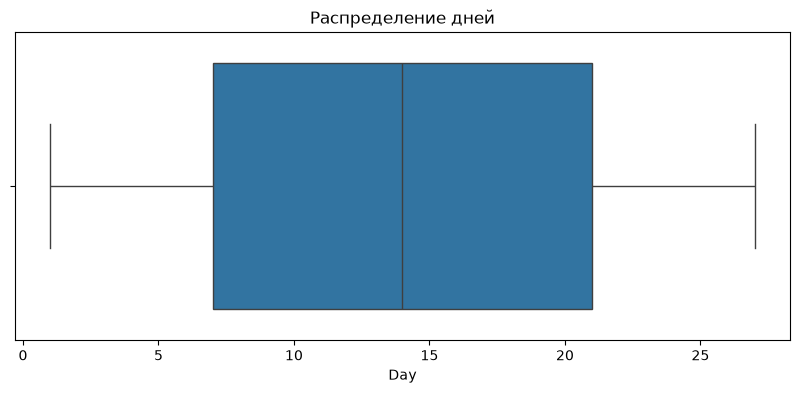

In [62]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_sessions["day"])

plt.title("Распределение дней")
plt.xlabel("Day")
plt.show()

In [63]:
df_clicks["time_passed"].describe()


count    100000.000000
mean       1391.033500
std        4013.418216
min           2.000000
25%          25.000000
50%         229.000000
75%        1338.000000
max      166227.000000
Name: time_passed, dtype: float64

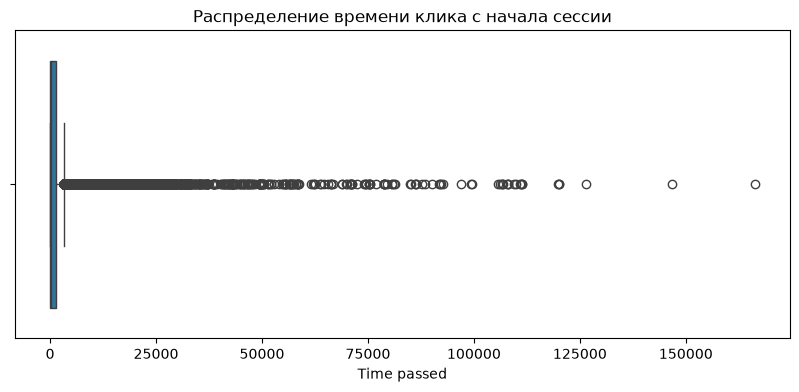

In [64]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clicks["time_passed"])

plt.title("Распределение времени клика с начала сессии")
plt.xlabel("Time passed")
plt.show()

Некоторые пользователи кликали значительно позднее остальных

In [59]:
df_queries["time_passed"].describe()

count    100000.000000
mean        761.599150
std        2628.893013
min           0.000000
25%           0.000000
50%           0.000000
75%         529.000000
max      119908.000000
Name: time_passed, dtype: float64

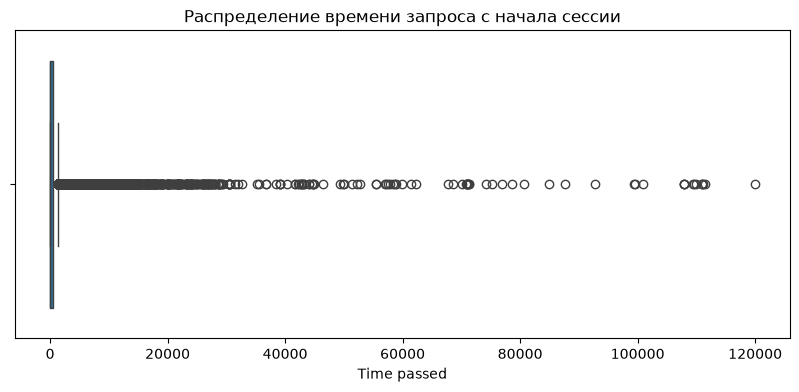

In [65]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_queries["time_passed"])

plt.title("Распределение времени запроса с начала сессии")
plt.xlabel("Time passed")
plt.show()

Некоторые пользователи отправляли запрос значительно позднее других

#### Посмотрим на самые популярные слова в запросах:

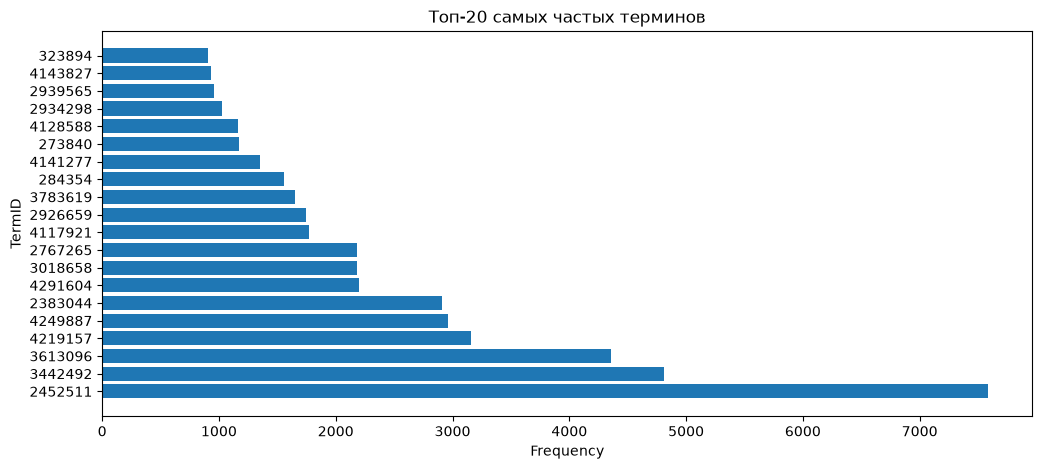

In [75]:
tokens = {}
for lst in df_queries["list_of_terms"]:
    for token in lst:
        if token in tokens:
            tokens[token] += 1
        else:
            tokens[token] = 1

top_tokens = sorted(tokens.items(), key=lambda x: x[1], reverse=True)[:20]
plt.figure(figsize=(12, 5))
plt.barh([str(x[0]) for x in top_tokens], [x[1] for x in top_tokens])
plt.title("Топ-20 самых частых терминов")
plt.ylabel("TermID")
plt.xlabel("Frequency")
plt.show()

#### Посмотрим на самые популярные домены и url в запросах:

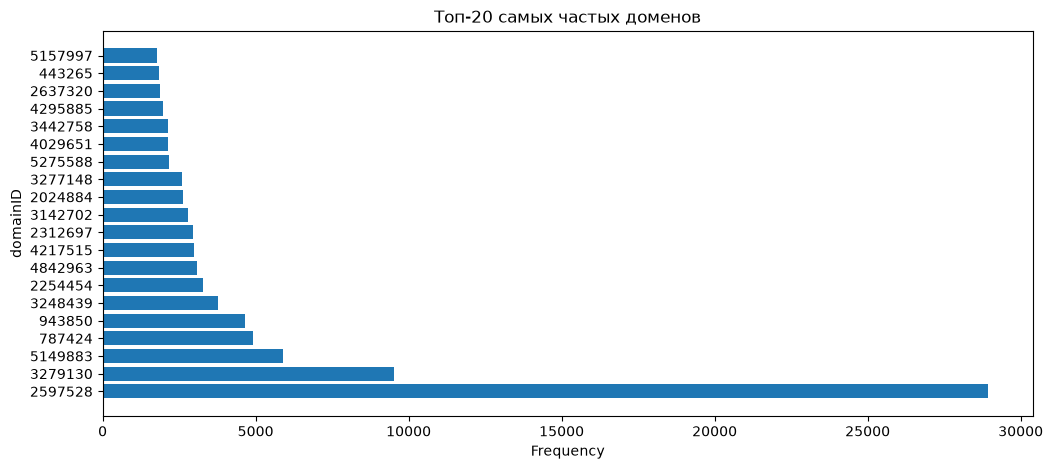

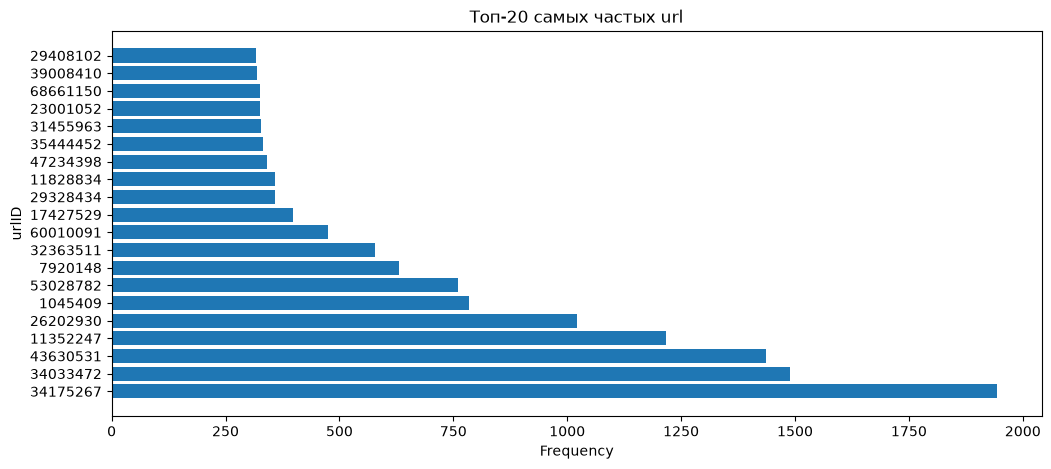

In [78]:
domains = {}
urls = {}
for lst in df_queries["url_domain_pairs"]:
    for (url, domain) in lst:
        if domain in domains:
            domains[domain] += 1
        else:
            domains[domain] = 1
        if url in urls:
            urls[url] += 1
        else:
            urls[url] = 1

top_domains = sorted(domains.items(), key=lambda x: x[1], reverse=True)[:20]
plt.figure(figsize=(12, 5))
plt.barh([str(x[0]) for x in top_domains], [x[1] for x in top_domains])
plt.title("Топ-20 самых частых доменов")
plt.ylabel("domainID")
plt.xlabel("Frequency")
plt.show()

top_urls = sorted(urls.items(), key=lambda x: x[1], reverse=True)[:20]
plt.figure(figsize=(12, 5))
plt.barh([str(x[0]) for x in top_urls], [x[1] for x in top_urls])
plt.title("Топ-20 самых частых url")
plt.ylabel("urlID")
plt.xlabel("Frequency")
plt.show()